# Logistic regression on prepared data

We train one logistic regression model using the existing prepared CSV files. Our inputs are `data/processed/train.csv` and `data/processed/test.csv`; we do not rebuild the data or compare feature-set variants here.

We keep the existing logarithmic follower and genre features as model inputs. Other stored columns remain available for reference. We evaluate on a held-out part of the labeled training file, then refit on the full training file and generate `delivery/predictions.csv` for the unlabeled test file.

Our retained preparation steps and studies are preserved in `notebooks/00_data_preparation.ipynb` and notebooks 01–07.

## 1. Configuration and imports

In [1]:
from pathlib import Path
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy.sparse import csr_matrix, hstack
from IPython.display import display, Image
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             RocCurveDisplay, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 0
THRESHOLD = 0.5
MAX_ITER = 1000
PROCESSED_DIR = next((directory for directory in (
    Path.cwd() / "data/processed", Path.cwd().parent / "data/processed", Path.cwd(),
) if all((directory / name).is_file() for name in ("train.csv", "test.csv"))), None)
if PROCESSED_DIR is None:
    raise FileNotFoundError("Set PROCESSED_DIR to the folder containing the prepared train.csv and test.csv.")
PROJECT_DIR = PROCESSED_DIR.parent.parent if PROCESSED_DIR.name == "processed" else Path.cwd()
REPORT_DIR = PROJECT_DIR / "reports/logistic_regression"
MODEL_DIR = PROJECT_DIR / "models"
DELIVERY_DIR = PROJECT_DIR / "delivery"
for directory in (REPORT_DIR, MODEL_DIR, DELIVERY_DIR):
    directory.mkdir(parents=True, exist_ok=True)


/home/goncalotorcato/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-ghdsbqv5 because there was an issue with the default path (/home/goncalotorcato/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 2. Load the prepared CSV files

We read the prepared train and test files and preserve their columns and row order. Existing genre indicators are stored sparsely in memory. We do not repeat data cleaning or select a new genre vocabulary.

In [2]:
train_header = pd.read_csv(PROCESSED_DIR / "train.csv", nrows=0).columns.tolist()
test_header = pd.read_csv(PROCESSED_DIR / "test.csv", nrows=0).columns.tolist()
GENRE_COLUMNS = [column for column in train_header if column.startswith("genre_")]
assert "music_hit" in train_header and "music_hit" not in test_header
assert [column for column in train_header if column != "music_hit"] == test_header
assert "release_year" in train_header and "release_date" not in train_header
assert "artist_followers_log1p" in train_header and "genre_unknown" in GENRE_COLUMNS


def load_prepared_csv(path, columns):
    # Read genre indicators in chunks and keep them sparse to limit memory use.
    parts = []
    for chunk in pd.read_csv(path, chunksize=10000, dtype={column: "uint8" for column in GENRE_COLUMNS}):
        values = chunk[GENRE_COLUMNS].to_numpy(dtype=np.uint8)
        assert ((values == 0) | (values == 1)).all()
        indicators = pd.DataFrame.sparse.from_spmatrix(
            csr_matrix(values), index=chunk.index, columns=GENRE_COLUMNS,
        )
        parts.append(pd.concat([chunk.drop(columns=GENRE_COLUMNS), indicators], axis=1)[columns])
    return pd.concat(parts, ignore_index=True)


model_train = load_prepared_csv(PROCESSED_DIR / "train.csv", train_header)
model_test = load_prepared_csv(PROCESSED_DIR / "test.csv", test_header)
assert model_train["id"].is_unique and model_test["id"].is_unique
assert not set(model_train["id"]).intersection(model_test["id"])
assert set(model_train["music_hit"].unique()) == {0, 1}
assert not model_train["duration_sec"].eq(0).any()
display(pd.DataFrame({
    "dataset": ["prepared train", "prepared test"],
    "rows": [len(model_train), len(model_test)],
    "columns": [model_train.shape[1], model_test.shape[1]],
}))


,dataset,rows,columns
0,prepared train,350049,1025
1,prepared test,87513,1024


## 3. Create one fixed validation split

The competition test file has no target. We therefore reserve approximately 20% of the prepared training data for evaluation, grouping identical prepared predictor rows together and stratifying groups by their majority label. The rest is used to fit the validation model.

In [3]:
# Group identical prepared predictor rows, excluding the identifier and target.
group_ids = pd.util.hash_pandas_object(model_train.drop(columns=["id", "music_hit"]), index=False)
group_summary = pd.DataFrame({
    "group_id": group_ids.to_numpy(),
    "target": model_train["music_hit"].to_numpy(),
}).groupby("group_id", sort=False)["target"].agg(["count", "sum"])
# Stratify groups by their majority label; mixed-label ties are assigned to class 1.
group_labels = (2 * group_summary["sum"] >= group_summary["count"]).astype(int)
training_groups, validation_groups = train_test_split(
    group_summary.index.to_numpy(), test_size=0.2, random_state=RANDOM_STATE,
    stratify=group_labels.to_numpy(),
)
is_validation = group_ids.isin(validation_groups)
train_part = model_train.loc[~is_validation].copy()
valid_part = model_train.loc[is_validation].copy()
y_train = train_part["music_hit"].to_numpy()
y_valid = valid_part["music_hit"].to_numpy()
assert not set(training_groups).intersection(validation_groups)
assert not set(train_part["id"]).intersection(valid_part["id"])
assert len(train_part) + len(valid_part) == len(model_train)
assert set(np.unique(y_train)) == {0, 1} and set(np.unique(y_valid)) == {0, 1}
split_summary = pd.DataFrame([
    {"subset": name, "rows": len(frame), "hit proportion": frame["music_hit"].mean()}
    for name, frame in (("training", train_part), ("validation", valid_part))
])
display(split_summary)
validation_split = pd.DataFrame({
    "id": model_train["id"].to_numpy(),
    "subset": np.where(is_validation.to_numpy(), "validation", "training"),
    "group_id": group_ids.to_numpy(),
})
validation_split.to_csv(REPORT_DIR / "validation_split.csv", index=False)


,subset,rows,hit proportion
0,training,280031,0.103389
1,validation,70018,0.103331


## 4. Define one fixed model input set

We use logarithmic followers and all existing genre columns alongside the prepared numeric/audio features. We exclude original followers, identifiers, the target, and high-cardinality names from inputs. Scaling, imputation, and small-category encoding are fitted on the training partition only.

In [4]:
NUMERIC_FEATURES = [
    "duration_sec", "release_year", "audio_dance", "audio_energy", "audio_loudness",
    "audio_speech", "audio_acoustic", "audio_instrumental", "audio_live",
    "audio_valence", "audio_tempo", "artist_followers_log1p",
]
CATEGORICAL_FEATURES = ["album_type", "audio_key", "time_signature"]
BINARY_FEATURES = ["audio_mode", "explicit_lyrics"]
INPUT_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert "id" not in INPUT_COLUMNS and "music_hit" not in INPUT_COLUMNS
assert "artist_followers" not in INPUT_COLUMNS


def fit_feature_map(frame):
    preprocessor = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("scaler", StandardScaler()),
        ]), NUMERIC_FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL_FEATURES),
        ("binary", "passthrough", BINARY_FEATURES),
    ], sparse_threshold=1.0)
    # Fit model-time transformations on the training partition only.
    matrix = csr_matrix(preprocessor.fit_transform(frame[INPUT_COLUMNS]), dtype=np.float64)
    genre_matrix = frame[GENRE_COLUMNS].sparse.to_coo().tocsr()
    matrix = hstack([matrix, genre_matrix], format="csr", dtype=np.float64)
    assert np.isfinite(matrix.data).all()
    return matrix, {
        "preprocessor": preprocessor, "input_columns": INPUT_COLUMNS.copy(),
        "genre_columns": GENRE_COLUMNS.copy(),
        "feature_names": preprocessor.get_feature_names_out().tolist() + GENRE_COLUMNS,
    }


def transform_features(frame, feature_map):
    matrix = csr_matrix(feature_map["preprocessor"].transform(frame[feature_map["input_columns"]]), dtype=np.float64)
    genre_matrix = frame[feature_map["genre_columns"]].sparse.to_coo().tocsr()
    matrix = hstack([matrix, genre_matrix], format="csr", dtype=np.float64)
    assert matrix.shape[1] == len(feature_map["feature_names"])
    assert np.isfinite(matrix.data).all()
    return matrix


def evaluate_probabilities(y, probabilities):
    predictions = (probabilities >= THRESHOLD).astype(int)
    return {
        "roc_auc": roc_auc_score(y, probabilities),
        "average_precision": average_precision_score(y, probabilities),
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0),
    }

def fit_logistic(matrix, target):
    model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=MAX_ITER, tol=1e-4, random_state=RANDOM_STATE)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        with threadpool_limits(limits=2):
            model.fit(matrix, target)
    if any(issubclass(item.category, ConvergenceWarning) for item in captured):
        raise RuntimeError("Logistic regression did not converge; review the solver settings before using these scores.")
    assert model.classes_.tolist() == [0, 1]
    return model

## 5. Train and evaluate logistic regression

We train one logistic regression configuration and calculate ROC AUC, average precision, accuracy, precision, recall, and F1 on the validation partition. Label-based metrics use threshold 0.5.

In [5]:
start = time.perf_counter()
X_train, feature_map = fit_feature_map(train_part)
X_valid = transform_features(valid_part, feature_map)
model = fit_logistic(X_train, y_train)
with threadpool_limits(limits=2):
    valid_probabilities = model.predict_proba(X_valid)[:, 1]
    training_probabilities = model.predict_proba(X_train)[:, 1]
validation_metrics = evaluate_probabilities(y_valid, valid_probabilities)
results_table = pd.DataFrame([{
    "model": "logistic_regression_prepared", **validation_metrics,
    "training_roc_auc": roc_auc_score(y_train, training_probabilities),
    "features": X_train.shape[1], "fit_seconds": time.perf_counter() - start,
    "iterations": int(model.n_iter_.max()),
}])
results_table.to_csv(REPORT_DIR / "metrics.csv", index=False)
display(results_table.round(5))
print(f"Validation ROC AUC: {validation_metrics['roc_auc']:.5f}")
print(f"Validation accuracy: {validation_metrics['accuracy']:.2%}")


Validation ROC AUC: 0.91643
Validation accuracy: 92.15%


,model,roc_auc,average_precision,accuracy,precision,recall,f1,training_roc_auc,features,fit_seconds,iterations
0,logistic_regression_prepared,0.91643,0.62718,0.92152,0.68095,0.45252,0.54372,0.92014,1035,3.33253,181


## 6. Inspect validation predictions

We inspect the ROC curve and confusion matrix for this single model and save the validation predictions.

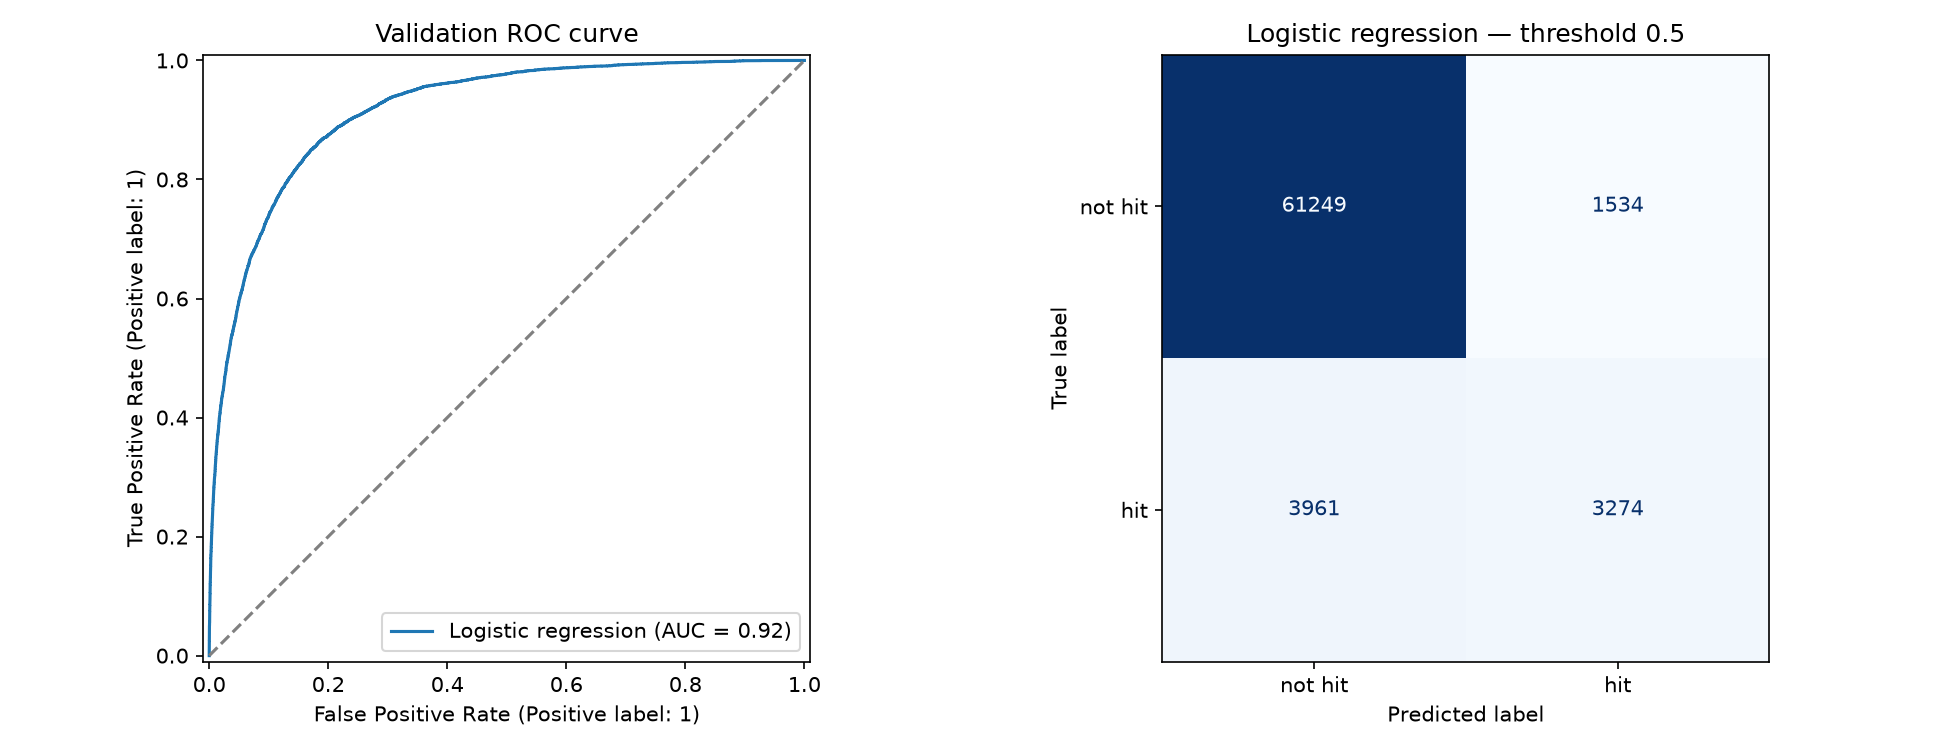

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
RocCurveDisplay.from_predictions(y_valid, valid_probabilities, name="Logistic regression", ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[0].set_title("Validation ROC curve")
ConfusionMatrixDisplay.from_predictions(
    y_valid, (valid_probabilities >= THRESHOLD).astype(int),
    display_labels=["not hit", "hit"], cmap="Blues", ax=axes[1], colorbar=False,
)
axes[1].set_title(f"Logistic regression — threshold {THRESHOLD}")
fig.tight_layout()
fig.savefig(REPORT_DIR / "validation_diagnostics.png", dpi=150)
plt.close(fig)
display(Image(filename=str(REPORT_DIR / "validation_diagnostics.png")))
pd.DataFrame({
    "id": valid_part["id"].to_numpy(), "music_hit": y_valid,
    "probability": valid_probabilities, "prediction": (valid_probabilities >= THRESHOLD).astype(int),
}).to_csv(REPORT_DIR / "validation_predictions.csv", index=False)


## 7. Refit and predict the prepared test file

We refit the same model configuration on the entire prepared training file. We then generate a probability for every prepared test ID and save the prediction CSV and fitted model.

In [7]:
# Release the holdout matrices before fitting the final model on all prepared training rows.
del X_train, X_valid, training_probabilities
X_full, final_feature_map = fit_feature_map(model_train)
final_model = fit_logistic(X_full, model_train["music_hit"].to_numpy())
X_test = transform_features(model_test, final_feature_map)
with threadpool_limits(limits=2):
    test_probabilities = final_model.predict_proba(X_test)[:, 1]
assert np.isfinite(test_probabilities).all()
assert ((test_probabilities >= 0) & (test_probabilities <= 1)).all()
submission = pd.DataFrame({"id": model_test["id"].to_numpy(), "music_hit": test_probabilities})
assert submission["id"].equals(model_test["id"])
assert len(submission) == len(model_test)
submission.to_csv(DELIVERY_DIR / "predictions.csv", index=False)
artifact = {
    "model": final_model, "feature_map": final_feature_map,
    "configuration": {"name": "logistic_regression_prepared", "input": "data/processed"},
    "threshold": THRESHOLD, "random_state": RANDOM_STATE, "sklearn_version": sklearn.__version__,
}
joblib.dump(artifact, MODEL_DIR / "logistic_regression.joblib")
pd.DataFrame({
    "feature": final_feature_map["feature_names"], "coefficient": final_model.coef_[0],
}).to_csv(REPORT_DIR / "coefficients.csv", index=False)
print(f"Final training rows: {len(model_train):,}; test predictions: {len(submission):,}")
display(submission.head())


Final training rows: 350,049; test predictions: 87,513


,id,music_hit
0,350052,0.015265
1,350053,0.594016
2,350054,0.623878
3,350055,0.599885
4,350056,0.608225


## 8. Record the results

We record the input files, fixed feature set, measured scores, and evaluation scope in the group report.

In [8]:
lines = [
    "# Logistic regression on the prepared datasets", "",
    "We evaluated one fixed logistic regression configuration using only `data/processed/train.csv` and "
    "`data/processed/test.csv`. We used the existing cleaning and feature-engineering results without rebuilding them "
    "or comparing alternative feature sets.", "",
    "## Inputs and features", "",
    f"The prepared training file contains {len(model_train):,} labeled rows and the test file contains {len(model_test):,} unlabeled rows. "
    "We used the prepared audio features, duration, release year, logarithmic followers, explicit-lyrics status, "
    "album type, musical key, mode, time signature, and all existing genre indicator columns. "
    "We kept original followers, IDs, titles, artist names, and record labels in the files but excluded them from model inputs. "
    "The target `music_hit` was used only as the response variable.", "",
    "## Validation", "",
    f"We used a fixed group-aware split with {len(train_part):,} training rows and {len(valid_part):,} validation rows. "
    "Identical prepared predictor rows share a group and cannot cross the split. We stratified groups by their majority label "
    f"using random state {RANDOM_STATE}; mixed-label ties were assigned to class 1. "
    "We fitted numerical imputation, continuous-feature scaling, and categorical encoding only on the training partition. "
    "The genre columns were already selected during preparation of the full training CSV, before this split. "
    "Our scores therefore evaluate the current prepared dataset rather than independently validating that earlier vocabulary-selection decision. "
    "We treat this reused development split as exploratory validation rather than an independent final estimate.", "",
    "We used regularized logistic regression with C=1, the lbfgs solver, a maximum of 1,000 iterations, "
    "and threshold 0.5 for label-based metrics. We used neither class weighting nor resampling.", "",
    "## Results", "",
    "| ROC AUC | Average precision | Accuracy | Precision | Recall | F1 | Training ROC AUC |",
    "| ---: | ---: | ---: | ---: | ---: | ---: | ---: |",
]
row = results_table.iloc[0]
lines.append(f"| {row['roc_auc']:.5f} | {row['average_precision']:.5f} | {row['accuracy']:.5f} | "
             f"{row['precision']:.5f} | {row['recall']:.5f} | {row['f1']:.5f} | {row['training_roc_auc']:.5f} |")
lines += [
    "", "## Final model and predictions", "",
    "We refitted the same configuration and its model-time preprocessing on all prepared training rows, "
    f"then generated {len(submission):,} probabilities for the prepared test file. We saved them to `delivery/predictions.csv` "
    "and saved the fitted model and feature map to `models/logistic_regression.joblib`. "
    "The competition test file has no target, so the reported metrics come from the validation partition. "
    "We did not alter the prepared CSV files or submit the predictions.", "",
]
(REPORT_DIR / "summary.md").write_text("\n".join(lines), encoding="utf-8")
print(f"Report saved to {REPORT_DIR / 'summary.md'}")


Report saved to /home/goncalotorcato/ist1109358/CD/Projeto/CD/reports/logistic_regression/summary.md
